In [1]:
import xmlrpc.client
import ssl
import pandas as pd  # On ajoute Pandas pour transformer les données en tableau

# --- CONFIGURATION ---
url = 'https://econostic1.odoo.com'
db = 'econostic1'
username = 'consultant.econostic@gmail.com'
password = 'wpV5*jZP$f#n8tj'

context = ssl._create_unverified_context()

try:
    # 1. Connexion et Authentification
    common = xmlrpc.client.ServerProxy(f"{url}/xmlrpc/2/common", context=context)
    uid = common.authenticate(db, username, password, {})
    
    if uid:
        print(f"✅ Connexion réussie (UID: {uid})")
        models = xmlrpc.client.ServerProxy(f"{url}/xmlrpc/2/object", context=context)
        
        # 2. Extraction des données
        print("--- Extraction des données en cours ---")
        model_name = 'sale.order'
        fields = ['name', 'date_order', 'partner_id', 'amount_total', 'state']
        
        # On récupère toutes les ventes (sans limite pour avoir un vrai tableau)
        sales_raw = models.execute_kw(db, uid, password, model_name, 'search_read', [[]], {'fields': fields})
        
        # 3. Transformation en DataFrame (Le fameux tableau)
        df = pd.DataFrame(sales_raw)
        
        # Nettoyage : partner_id arrive comme [ID, "Nom"], on ne garde que le "Nom"
        if not df.empty:
            df['client'] = df['partner_id'].apply(lambda x: x[1] if isinstance(x, list) else x)
            
            # On sélectionne les colonnes qui nous intéressent pour y voir clair
            df_final = df[['name', 'date_order', 'client', 'amount_total', 'state']]
            
            print("\n--- Ton tableau de données (DataFrame Pandas) ---")
            print(df_final.head()) # Affiche les 5 premières lignes
            
            print("\n--- Statistiques rapides ---")
            print(f"Nombre total de ventes : {len(df_final)}")
            print(f"Chiffre d'affaires total : {df_final['amount_total'].sum()} €")
        else:
            print("Aucune vente trouvée dans Odoo.")
            
    else:
        print("❌ Échec : Identifiants incorrects.")

except Exception as e:
    print(f"❌ Erreur : {e}")

✅ Connexion réussie (UID: 2)
--- Extraction des données en cours ---

--- Ton tableau de données (DataFrame Pandas) ---
     name           date_order            client  amount_total state
0  S00017  2026-01-29 10:30:00  Gemini Furniture        1186.5  sale
1  S00015  2026-01-29 10:30:00  Gemini Furniture        1582.0  sale
2  S00014  2026-01-29 10:30:00  Gemini Furniture         415.5  sale
3  S00013  2026-01-29 10:30:00  Gemini Furniture         556.0  sale
4  S00011  2026-01-29 10:30:00  Gemini Furniture         751.0  sale

--- Statistiques rapides ---
Nombre total de ventes : 21
Chiffre d'affaires total : 28720.820000000003 €


In [2]:
# Groupement par client et somme des achats
top_clients = df.groupby('client')['amount_total'].sum().sort_values(ascending=False)
print(top_clients)

client
Gemini Furniture    15372.48
Joel Willis          5390.63
Ready Mat            4628.46
Acme Corporation     2466.75
Lumber Inc            862.50
CHADIA                  0.00
Name: amount_total, dtype: float64


<Axes: title={'center': 'Ventes par jour'}, xlabel='date_order'>

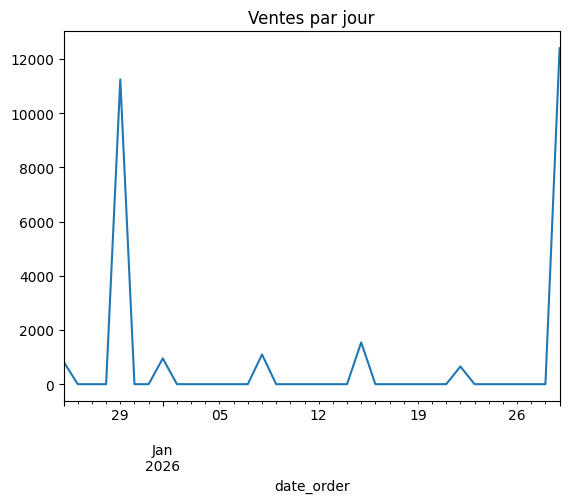

In [4]:
# Conversion de la date en format lisible par Pandas
df['date_order'] = pd.to_datetime(df['date_order'])
df.resample('D', on='date_order')['amount_total'].sum().plot(kind='line', title='Ventes par jour')

In [6]:
from groq import Groq
import os

# 1. Configuration de l'IA
client = Groq(api_key="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")

def agent_pilote_performance(question, dataframe):
    # On transforme les données Odoo en texte pour l'IA
    donnees_contexte = dataframe.to_string()
    
    prompt = f"""
    Tu es un Expert en Pilotage de Performance. 
    Voici les données de ventes actuelles de l'ERP Odoo :
    {donnees_contexte}
    
    Question de l'utilisateur : {question}
    
    Réponds en français. Structure ta réponse ainsi :
    1. Constat (chiffres clés)
    2. Analyse (ce qui va ou ne va pas)
    3. Recommandation stratégique.
    """
    
    try:
        chat_completion = client.chat.completions.create(
            messages=[{"role": "user", "content": prompt}],
            model="llama-3.3-70b-specdec", # Modèle ultra-performant visible sur ton image
        )
        return chat_completion.choices[0].message.content
    except Exception as e:
        return f"Erreur : {e}"


# --- TEST DE L'AGENT ---
ma_question = "Fais-moi un résumé de ma performance et dis-moi qui est mon client le plus rentable."
reponse = agent_pilote_performance(ma_question, df)

print("🤖 AGENT IA :")
print(reponse)

🤖 AGENT IA :
Erreur : Error code: 400 - {'error': {'message': 'The model `llama-3.3-70b-specdec` has been decommissioned and is no longer supported. Please refer to https://console.groq.com/docs/deprecations for a recommendation on which model to use instead.', 'type': 'invalid_request_error', 'code': 'model_decommissioned'}}


In [8]:
from groq import Groq

client = Groq(api_key="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")

# On prépare la question et les données
question = "Analyse ma performance actuelle et ma dépendance client. Propose une stratégie."
donnees_contexte = df.to_markdown() # Plus propre pour l'IA que to_string()

completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
      {
        "role": "system",
        "content": "Tu es un Expert en Pilotage de Performance. Réponds en français de manière structurée."
      },
      {
        "role": "user",
        "content": f"Voici mes données Odoo :\n{donnees_contexte}\n\nQuestion : {question}"
      }
    ],
    temperature=0.7, # Un peu plus bas pour être plus précis sur les chiffres
    max_completion_tokens=8192,
    top_p=1,
    reasoning_effort="medium",
    stream=True
)

print("🤖 ANALYSE DU GPT-OSS-120B :\n")
for chunk in completion:
    print(chunk.choices[0].delta.content or "", end="")

🤖 ANALYSE DU GPT-OSS-120B :

## 1️⃣ Analyse de la performance actuelle  

| KPI | Calcul | Résultat |
|-----|--------|----------|
| **Chiffre d’affaires confirmé** (états *sale* + *sent*) | Σ amount_total des lignes confirmées | **21 625,61 €** |
| **Nombre de ventes confirmées** | lignes *sale* + *sent* | **16** |
| **Valeur moyenne d’une vente** | CA / Nb ventes | **1 351,60 €** |
| **Taux de conversion** (ventes / total opportunités) | 16 / 21 ≈ **76 %** |
| **Répartition du CA par client** | Σ amount_total par client | <ul><li>**Gemini Furniture** : 15 372,48 € (71 % du CA)</li><li>**Joel Willis** : 5 390,63 € (25 %)</li><li>**Lumber Inc** : 862,50 € (4 %)</li></ul> |
| **Potentiel en cours (draft)** | Σ amount_total des lignes *draft* | **7 095,21 €** |
| **Dépendance client** | % du CA provenant du principal client | **71 %** (Gemini) |

### Points forts
| ✔️ | Observation |
|---|--------------|
| **Taux de conversion élevé** (76 %) | La plupart des opportunités aboutissent à une